# Inference : classification (BioCLIP) + CAM + segmentation SAM sur MINKA

Pipeline pour une photo MINKA :
1. **Classification** de la famille avec le modèle **BioCLIP déjà fine-tuné** (`best_family_bioclip.pth`) ;
2. **CAM** (Grad-CAM adapté au ViT de BioCLIP) pour la famille prédite ;
3. **SAM** : les points les plus chauds de la CAM servent de prompts pour obtenir un masque précis de l'organisme.

## For Google Collab Only

In [ ]:
import os, sys

if "google.colab" in sys.modules:
    if not os.path.exists("ANERIS_BrugesWORKSHOP"):
        !git clone https://github.com/PerrineGilloteaux/ANERIS_BrugesWORKSHOP.git
    %cd ANERIS_BrugesWORKSHOP
    !pip install -q -r requirementsColab.txt

## 1. Loading once the models (BioCLIP + SAM)

In [3]:
import os, time, urllib.request
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from AEIS_MAC_libforminka import (
    read_image, load_model_from_checkpoint, load_predictor,
    refine_mask_with_sam, display_results,
    _preprocess, _model_transform, _normalize_stats, download_if_missing, analyse_image
)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device :", device)

# --- Fichiers (téléchargés une seule fois s'ils sont absents) ---
MODEL_PATH = "models/best_family_bioclip.pth"
MODEL_URL  = "https://zenodo.org/records/23236454/files/best_family_bioclip.pth?download=1"
SAM_PATH   = "sam_vit_h_4b8939.pth"
SAM_URL    = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"


download_if_missing(MODEL_URL, MODEL_PATH)
download_if_missing(SAM_URL, SAM_PATH)

# --- BioCLIP fine-tuné (le checkpoint contient la config, les poids et la liste des familles) ---
model, _, epoch, _, class_names = load_model_from_checkpoint(MODEL_PATH, device=device)
model.eval()
if class_names is None:                      # sécurité : ancien checkpoint sans class_names
    import pickle
    class_names = pickle.load(open("labels_and_encoder.pkl", "rb"))["class_names"]
print(f"{type(model).__name__} chargé (epoch {epoch + 1}), {len(class_names)} familles")

# --- SAM (sur GPU si disponible : load_predictor le laisse sur CPU) ---
predictor = load_predictor(SAM_PATH)
predictor.model.to(device)
print("SAM chargé")

Device : cpu
BioCLIPClassifier chargé (epoch 8), 365 familles
SAM chargé


## 2. Inference

Look for a picture on the MINKA database , and click on the "i" to get the picture number, copy paste it under PHOTO_IDS

`TH` is the threshold on the selectivity of the CAM (between 0 all and 1 nothing)

`B` is the block/ layer of attention where to look at (-3 to 1 usually)

Échec : https://observe.minka-sdg.org/attachments/local_photos/files/956547/medium.jpg
Image OK : https://observe.minka-sdg.org/attachments/local_photos/files/956547/medium.jpeg
Famille prédite : Aeolidiidae (85.3%)
   alternative : Acanthochitonidae (0.4%)
   alternative : Facelinidae (0.4%)
Temps : classification 0.6s | CAM 0.5s | SAM 16.0s
mask Area : 77207 pixels | Image Area : 187500 pixels | Ratio : 0.4118 (41.18%)


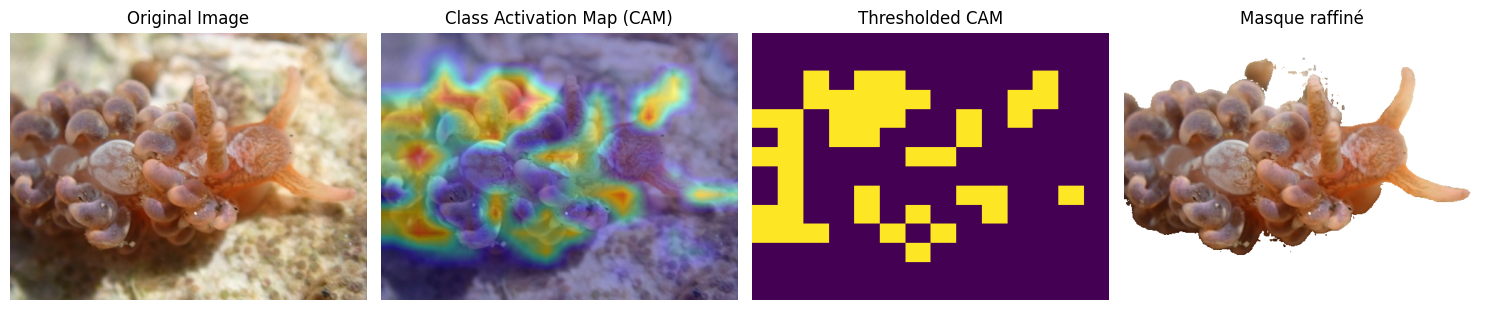

In [4]:
PHOTO_IDS = ["956547"]     # numéros de photo MINKA (ou URL complète, ou chemin local)
TH = 0.5                # seuil CAM -> points SAM
B=-2
results = {}
for pid in PHOTO_IDS:
    results[pid] = analyse_image(pid, model, device, class_names, predictor, th=TH, block=B )